# Lecture 14, Scenarios, climate sensitivity and uncertainty, and CMIP7

> What drives the projections, why models disagree, and what comes next

Lecture 13 described how CMIP is organised. This lecture looks at what makes the numbers differ:

1. the **scenarios** that describe the future forcing, from SRES through RCP and SSP to CMIP7,
2. the **climate sensitivity** of a model, which decides how much it warms for a given forcing,
3. the three sources of **uncertainty** (internal variability, model, scenario), and what they mean for hydrology,
4. the step from a global model to a **catchment** (worked through in Lectures 16&ndash;23), and
5. **CMIP7**, the phase now getting under way.

The code cells reuse the energy balance model of Lecture 4 as a small laboratory in which these ideas can be tested.


In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1) Scenarios: describing the future forcing

Climate models cannot predict how much CO$_2$ people will emit, so projections are made **conditional on a scenario**, a self-consistent description of future emissions or concentrations. Recall from Lecture 4 that the forcing from CO$_2$ is $F = a \ln(\mathrm{CO_2}/\mathrm{CO_{2,PI}})$ with $a \approx 5$ W m$^{-2}$, and that the **radiative forcing** is the imbalance between energy coming in and going out. The scenario families of the last three CMIP phases differ in how they define the forcing.

### SRES (CMIP3, 2000)
The *Special Report on Emissions Scenarios* defined four storyline families from two choices: more economic or more environmental emphasis, and more global or more regional development.

| Family | Story |
|:--|:--|
| **A1** | Rapid economic growth, a convergent world and rapid spread of new technology. Subsets by energy emphasis: **A1FI** fossil-intensive, **A1B** balanced, **A1T** non-fossil. |
| **A2** | A divided world of self-reliant nations, rising population, regionally oriented development and high emissions. |
| **B1** | An integrated and more ecologically friendly world, with a shift to a service and information economy and clean technology. |
| **B2** | A divided but ecologically friendly world: local solutions, slower population growth, intermediate development. |

SRES scenarios started from socio-economic stories and *calculated* emissions and then concentrations, with no climate-policy assumptions.

### RCPs (CMIP5, 2011)
The **Representative Concentration Pathways** reversed the order. They specify *concentration* (radiative forcing) pathways first, named by the forcing reached in 2100 in W m$^{-2}$: **RCP2.6** (strong mitigation, aimed at keeping warming below about 2 &deg;C), **RCP4.5** and **RCP6.0** (intermediate stabilisation) and **RCP8.5** (high emissions). Several socio-economic stories can lead to the same pathway, so the pathways are "representative" rather than predictions.

### SSPs (CMIP6, 2016)
The **Shared Socioeconomic Pathways** put the two ideas together. Each **SSP** is a socio-economic narrative; it is combined with a **forcing level** as in the RCPs, so the name of a scenario carries both, for example **SSP2-4.5** is "middle of the road" development with 4.5 W m$^{-2}$ of forcing in 2100. The point is that the same forcing level can be reached by different societies, with very different *challenges for mitigation and adaptation*, which matters for impact studies.

| SSP | Narrative | Challenge |
|:--|:--|:--|
| **SSP1** | Sustainability, "taking the green road" | low for both mitigation and adaptation |
| **SSP2** | Middle of the road | intermediate |
| **SSP3** | Regional rivalry, "a rocky road" | high for both |
| **SSP4** | Inequality, "a road divided" | low mitigation challenge, high adaptation challenge |
| **SSP5** | Fossil-fuelled development, "taking the highway" | high mitigation challenge, low adaptation challenge |

ScenarioMIP, the CMIP6-Endorsed MIP for scenarios, gives top priority (Tier 1) to four combinations that span the range: **SSP1-2.6, SSP2-4.5, SSP3-7.0 and SSP5-8.5**. Other combinations (for example SSP1-1.9, which aims at 1.5 &deg;C, and SSP4-3.4, SSP4-6.0 and SSP5-3.4OS) have a lower priority. You have already forced the energy balance model with the four Tier-1 CO$_2$ pathways in Lecture 4 and compared its warming with the CMIP6 multi-model mean; the plot below puts the three generations of scenario names side by side using their end-of-century radiative forcing.

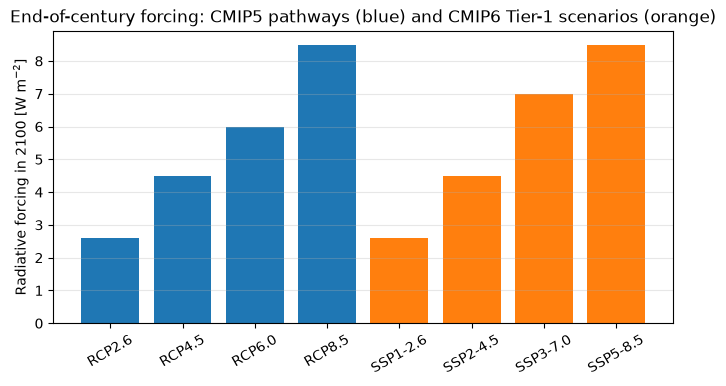

In [3]:
forcing_2100 = {                       # radiative forcing in 2100 [W/m2], from the scenario names
    "RCP2.6": 2.6, "RCP4.5": 4.5, "RCP6.0": 6.0, "RCP8.5": 8.5,
    "SSP1-2.6": 2.6, "SSP2-4.5": 4.5, "SSP3-7.0": 7.0, "SSP5-8.5": 8.5,
}
colors = ["tab:blue"] * 4 + ["tab:orange"] * 4
plt.figure(figsize=(8, 3.8))
plt.bar(list(forcing_2100), list(forcing_2100.values()), color=colors)
plt.ylabel("Radiative forcing in 2100 [W m$^{-2}$]")
plt.title("End-of-century forcing: CMIP5 pathways (blue) and CMIP6 Tier-1 scenarios (orange)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3);

Notice that SSP1-2.6, SSP2-4.5 and SSP5-8.5 reach the *same forcing* as RCP2.6, RCP4.5 and RCP8.5. That was deliberate, to allow comparison between CMIP5 and CMIP6. SSP3-7.0 fills the gap between RCP6.0 and RCP8.5. What is new is not the forcing but the narrative attached to it and the updated emissions and land-use inputs.

# 2) Climate sensitivity

Two models given the *same* forcing can warm by different amounts. The most important number that separates them is the **equilibrium climate sensitivity (ECS)**: the long-term global warming after CO$_2$ is doubled and the climate has come into balance. A second number, the **transient climate response (TCR)**, is the warming at the moment CO$_2$ has doubled in a run in which it rises by 1 % per year, (about 70 years); it is smaller than ECS because the ocean has not yet caught up.

In the energy balance model of Lecture 4,

$$C\,\frac{dT}{dt} = F - \lambda\,\Delta T,\qquad \lambda = -B,$$

the forcing $F$ pushes the temperature up and the **feedback parameter** $\lambda$ (W m$^{-2}$ K$^{-1}$) pulls it back (the net radiative response of the planet per degree of warming). In equilibrium $C\,dT/dt = 0$, so

$$\mathrm{ECS} = \frac{F_{2\times}}{\lambda}, \qquad F_{2\times} = a\ln 2 .$$

A larger $\lambda$ means a stronger restoring response and a smaller ECS; a feedback that amplifies warming (clouds, water vapour, snow and ice) *reduces* $\lambda$. The spread of ECS in CMIP models therefore reflects the spread in the feedback parameter, and the largest part of that spread comes from clouds (the focus of CFMIP).

### How CMIP measures it: abrupt-4xCO2 and the Gregory plot

The `abrupt-4xCO2` experiment gives a large, clean signal. The energy imbalance at the top of the atmosphere is $N = F - \lambda\,\Delta T$, which is a straight line against the warming $\Delta T$ (a **Gregory plot**). The intercept on the vertical axis is the forcing of the experiment, and the intercept on the horizontal axis is the warming at equilibrium for quadrupled CO$_2$. In a model with a single heat-capacity layer the line is exact; in a real model it curves because the feedbacks change with time and with the pattern of warming, and the sensitivity is estimated by fitting the line over, for example, the first 150 years. The cell below does this for the Lecture 4 model.

forcing for 4xCO2 : 6.93 W/m2 (the vertical intercept)
equilibrium warming for 4xCO2 : 5.33 K (the horizontal intercept)
ECS = half of that  : 2.67 K   (= a ln2 / lambda = 2.67 K)


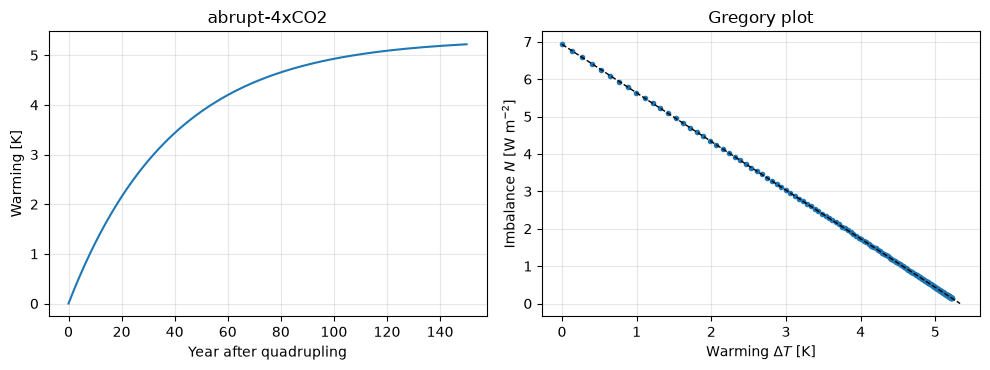

In [4]:
# Energy balance model of Lecture 4, written as a short function
S, alpha, a, CO2_PI, C, T0 = 1368.0, 0.3, 5.0, 280.0, 51.0, 14.0
absorbed = S * (1 - alpha) / 4

def run_ebm(co2, B=-1.3, noise=0.0, seed=None, T_init=T0):
    A = absorbed + B * T0
    rng = np.random.default_rng(seed)
    T = np.empty(len(co2))
    T[0] = T_init
    for n in range(1, len(co2)):
        forcing = a * np.log(co2[n - 1] / CO2_PI)
        N = absorbed - (A - B * T[n - 1]) + forcing
        T[n] = T[n - 1] + (N + noise * rng.standard_normal()) / C
    return T

years = np.arange(0, 151)
lam = 1.3                                              # feedback parameter, W/m2/K (= -B)
T = run_ebm(np.full(years.size, 4 * CO2_PI))           # abrupt 4xCO2
dT = T - T0
F4x = a * np.log(4)
N = F4x - lam * dT                                     # top-of-atmosphere imbalance

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(years, dT)
ax1.set_xlabel("Year after quadrupling"); ax1.set_ylabel("Warming [K]"); ax1.set_title("abrupt-4xCO2"); ax1.grid(alpha=0.3)
ax2.plot(dT, N, "o", ms=3)
ax2.plot([0, F4x / lam], [F4x, 0], "k--", lw=1)
ax2.set_xlabel("Warming $\\Delta T$ [K]"); ax2.set_ylabel("Imbalance $N$ [W m$^{-2}$]")
ax2.set_title("Gregory plot"); ax2.grid(alpha=0.3)
fig.tight_layout()
print(f"forcing for 4xCO2 : {F4x:.2f} W/m2 (the vertical intercept)")
print(f"equilibrium warming for 4xCO2 : {F4x/lam:.2f} K (the horizontal intercept)")
print(f"ECS = half of that  : {F4x/lam/2:.2f} K   (= a ln2 / lambda = {a*np.log(2)/lam:.2f} K)")

Now the **TCR** from a `1pctCO2` run, and the effect of the feedback parameter on both numbers.

TCR (warming at year 70) = 1.42 K   vs   ECS = 2.67 K


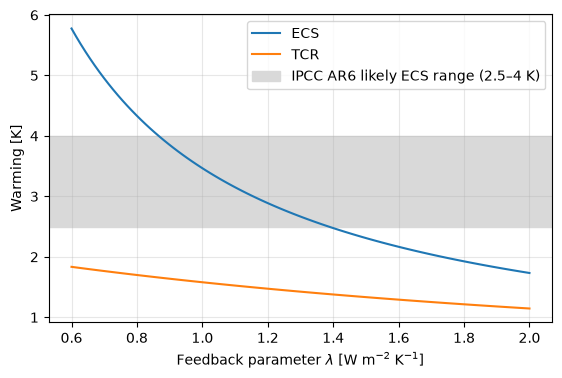

In [5]:
t = np.arange(0, 141)
co2_1pct = CO2_PI * 1.01 ** t                          # 1 % per year, doubles after ~70 years
T1 = run_ebm(co2_1pct)
print(f"TCR (warming at year 70) = {T1[70]-T0:.2f} K   vs   ECS = {a*np.log(2)/lam:.2f} K")

lams = np.linspace(0.6, 2.0, 100)
ecs = a * np.log(2) / lams
tcr = [run_ebm(co2_1pct, B=-l)[70] - T0 for l in lams]
plt.figure(figsize=(6.5, 4))
plt.plot(lams, ecs, label="ECS")
plt.plot(lams, tcr, label="TCR")
plt.axhspan(2.5, 4.0, color="0.85", label="IPCC AR6 likely ECS range (2.5–4 K)")
plt.xlabel("Feedback parameter $\\lambda$ [W m$^{-2}$ K$^{-1}$]")
plt.ylabel("Warming [K]")
plt.legend(); plt.grid(alpha=0.3);

The transient response is always smaller than the equilibrium response and varies less with $\lambda$, because over 70 years the ocean heat uptake, not the feedback, limits the warming. The shaded band is the range of ECS the IPCC AR6 judged *likely* (2.5 to 4 K, best estimate 3 K), and it corresponds, in this simple model, to a modest range of $\lambda$. Small differences in how clouds respond translate into large differences in projected warming.

### What CMIP showed

| Phase | ECS range of the models (approx.) | Comment |
|:--|:--|:--|
| CMIP3 | ~2.1&ndash;4.4 K | |
| CMIP5 | ~2.1&ndash;4.7 K | |
| CMIP6 | ~1.8&ndash;5.6 K | A number of models were *above* the highest value in CMIP5 (a "hot model" group), largely through changed cloud feedbacks |

The AR6 assessed ECS from several lines of evidence (process understanding, the historical record, paleoclimate, and the models) and concluded 2.5 to 4 K (likely), 2 to 5 K (very likely), best estimate 3 K. In its projections it therefore **did not simply average the CMIP6 models**: the warming assessed for each scenario was constrained using observations and the assessed ECS and TCR. The lesson for a user of CMIP data is that a model with a very high sensitivity runs hot in all scenarios, so models are sometimes weighted, screened or at least inspected for their sensitivity.

# 3) Uncertainty: three sources

When two projections differ, the difference has one of three origins (Hawkins and Sutton, 2009):

| Source | What it is | Reduced by |
|:--|:--|:--|
| **Internal variability** | Chaotic variations of the atmosphere and ocean (El Ni&ntilde;o, the monsoon's year-to-year changes, decadal swings) that would occur even with constant forcing | *Not reducible*. It can only be averaged by using many ensemble members or long periods. |
| **Model (response) uncertainty** | Different models respond differently to the same forcing, because of different feedbacks and processes | Better models and observational constraints |
| **Scenario uncertainty** | Future emissions are not known | Not a scientific uncertainty. It depends on human choices. |

Their importance changes with the **lead time**, the **region** and the **variable**. In the next decade internal variability dominates; by the end of the century and for global mean temperature, the scenario dominates. For *regional precipitation*, internal variability and model differences remain large for decades, so a "projected change" in rainfall over a district may be smaller than the natural year-to-year swings. This is why hydrological studies use many members and many models.

The cell below shows each source separately with the energy balance model. Internal variability is represented by random forcing (a standard stochastic model of climate noise); **model** differences by different feedback parameters; **scenario** differences by different CO$_2$ pathways. This is a toy: there is no ENSO or monsoon, only a plausible amount of year-to-year noise (about 0.13 K).

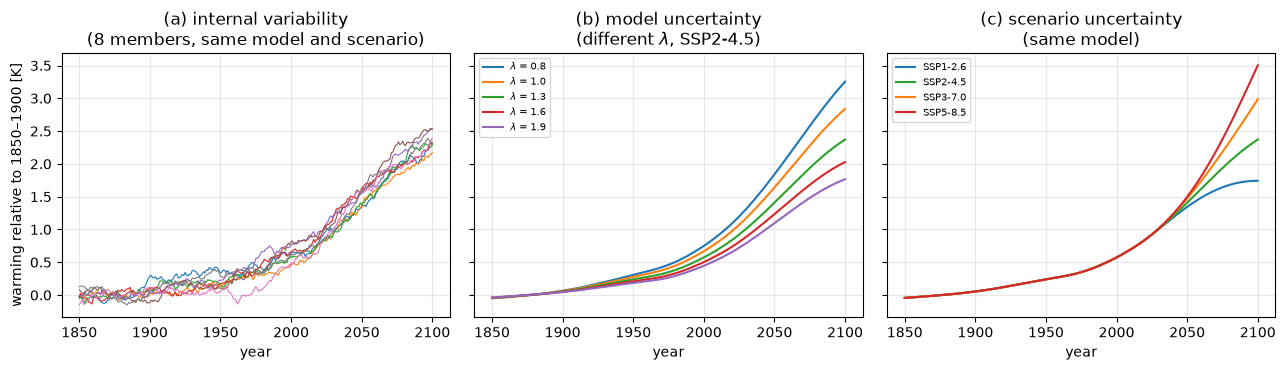

In [6]:
try:
    co2_tab = pd.read_csv("data/ssp_co2_concentrations.csv", comment="#")
except FileNotFoundError:   # e.g. on Colab without the repository
    co2_tab = pd.read_csv("https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/ssp_co2_concentrations.csv", comment="#")

yrs = co2_tab["year"].to_numpy()
def baseline(T):                                        # warming relative to 1850-1900
    return T - T[: 51].mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)

# (a) internal variability: same model, same scenario, different noise
for seed in range(8):
    T = run_ebm(co2_tab["SSP2-4.5"].to_numpy(), noise=1.4, seed=seed)
    axes[0].plot(yrs, baseline(T), lw=0.8)
axes[0].set_title("(a) internal variability\n(8 members, same model and scenario)")

# (b) model uncertainty: different feedback parameters, no noise
for lam_ in (0.8, 1.0, 1.3, 1.6, 1.9):
    T = run_ebm(co2_tab["SSP2-4.5"].to_numpy(), B=-lam_)
    axes[1].plot(yrs, baseline(T), label=f"$\\lambda$ = {lam_}")
axes[1].set_title("(b) model uncertainty\n(different $\\lambda$, SSP2-4.5)"); axes[1].legend(fontsize=7)

# (c) scenario uncertainty: different CO2 pathways, same model, no noise
for name, c in zip(["SSP1-2.6", "SSP2-4.5", "SSP3-7.0", "SSP5-8.5"], ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    axes[2].plot(yrs, baseline(run_ebm(co2_tab[name].to_numpy())), color=c, label=name)
axes[2].set_title("(c) scenario uncertainty\n(same model)"); axes[2].legend(fontsize=7)

for ax in axes:
    ax.set_xlabel("year"); ax.grid(alpha=0.3)
axes[0].set_ylabel("warming relative to 1850–1900 [K]")
fig.tight_layout();

Panel (a) shows why a single run proves little: eight members of the same model and scenario differ by about 0.1&ndash;0.2 K in any year, as much as the warming that accumulates in five to ten years, and individual members can stall or dip for a decade. Panel (b) shows that, for one scenario, plausible differences in the feedback parameter already spread the end-of-century warming by about 1.5 K. Panel (c) shows that the scenarios are indistinguishable until about 2040 and then diverge, so the scenario choice matters for the end of the century but hardly for the next two decades.

CMIP handles this by archiving several members per model (the `r` in the variant label, Lecture 13) and by comparing many models. It is an **ensemble of opportunity**, not a random sample of possible models: models share code, ancestors and ideas, so 30 models are not 30 independent estimates.

# 4) From the global model to a catchment

The distance between a CMIP grid cell and a gauged catchment is large in space (Lecture 13), in time (the models produce daily or monthly values, but their *day-to-day* weather is not a forecast) and in statistics (models are biased). Before the output reaches a hydrological model such as those of Lectures 7 and 8 it is therefore post-processed in one of three ways:

- **Bias correction**: compare the model's historical period with observations and adjust the model output (scaling the mean, or mapping the whole distribution by *quantile mapping*), then apply the same correction to the future.
- **Statistical downscaling**: use relationships between large-scale predictors and local rainfall or temperature, fitted on observations.
- **Dynamical downscaling**: run a high-resolution regional climate model inside the global one (CORDEX). Ready-made products such as NASA's NEX-GDDP-CMIP6 exist.

The simplest way to use projections for a design problem is the **delta-change method**: keep the observed series and scale it by the *change* the models project between a reference and a future period (for example +10 % in monthly rainfall, +2 &deg;C in temperature). It keeps the observed weather and uses the model only for the change; its weakness is that it cannot change how often it rains.

Every one of these methods rests on assumptions (above all that the model's bias is the same in the future as in the past), and none of them can repair a poor model. **Lectures 16&ndash;23** treat downscaling and bias correction in detail, each method with worked numbers in a spreadsheet and in Python.


# 5) CMIP7

CMIP6 reached the end of its useful life as the basis for the next IPCC cycle, and a new phase, **CMIP7**, has been designed to support the IPCC's **Seventh Assessment Report (AR7)**. This section describes the plan as published in 2025 and early 2026; the protocol is still evolving, so consult the CMIP pages for the latest version.

```{warning} Status
CMIP7 is under way at the time of writing (October 2026). Model simulations were being prepared and started in 2026 and the schedule depends on the timeline the IPCC sets for AR7, so details of data availability and even of scenario names may have changed since this lecture was written.
```

### Why a new phase?

- **A new assessment cycle** needs up-to-date models and forcing data. The historical forcing of CMIP6 stops in 2014; CMIP7 is harmonising forcing datasets that run to at least 2021.
- **Lessons from CMIP6.** The "hot model" problem showed that raw sensitivity matters; the community also asked for more *rapid* delivery of results to the assessment.
- **Updated scenarios.** The SSP scenarios date from 2016. Emissions since then, and the policy landscape, have changed, and the very-high end of CMIP6 (SSP5-8.5) is now considered less plausible than it was.
- **Infrastructure.** The archive and its software (ESGF) are being modernised; the CMIP6 archive was closed to new data in 2025 to free resources for CMIP7.

### What is different

| | CMIP6 | CMIP7 |
|:--|:--|:--|
| **Core** | DECK + historical = the entry card | **DECK refreshed and kept as the entry card**. Proposed updates include CO$_2$-emissions-driven simulations (for example `esm-hist`) and experiments to measure effective radiative forcing (`piClim`). |
| **Assessment** | Everything done on its own schedule, then analysed | An **Assessment Fast Track (AFT)**: a subset of experiments, taken from the community MIPs and chosen for their **timing**, to supply the IPCC AR7 and climate-service users first. Optional for modelling centres. |
| **Evaluation** | After the data are published | A **Rapid Evaluation Framework (REF)** to evaluate the Fast Track output quickly when it arrives. |
| **Scenarios** | SSP-based (SSP1-2.6, ..., SSP5-8.5) | A **new ScenarioMIP set** (see below), endorsed by the WCRP in February 2025 |
| **Emphasis** | Forcing-driven runs | More **emissions-driven** runs to study carbon-cycle feedbacks, and the response to net-zero and **negative emissions** (the *transient climate response to cumulative emissions*, TCRE) |
| **Data system** | ESGF | A new generation of ESGF with a revised data request |

### The CMIP7 scenarios

The new scenario set covers a range from high to very low emissions and **includes low-emission scenarios that overshoot** a temperature level before returning to it, with negative emissions, relevant to the Paris Agreement. The scenarios are also *extended beyond 2100* to study longer-term consequences such as sea-level rise. Unlike the SSP names, the new labels describe the *level* of emissions (High, Medium, Medium-Low, Low, Very Low) rather than a forcing number. The February 2025 endorsement named six trajectories (High, Medium, Medium-Low, Low, and two Very-Low variants with different amounts of overshoot); in late 2025 the labels were revised and a High-Low trajectory was added. Use the labels given by ScenarioMIP when you cite them.

### What to expect as a hydrologist

- A new generation of model output, with updated forcing data and probably new biases and sensitivities to examine, so expect the same checks you learnt here (sensitivity, evaluation against observations, bias correction) to apply again.
- The CMIP6 archive will remain the main resource for impact studies for several years while CMIP7 data arrive. A study that mixes CMIP6 and CMIP7 must state which scenarios it matches.
- For studies of low-emission futures and overshoot, CMIP7 will provide experiments that CMIP6 did not.

## Summary

- Projections are **conditional on a scenario**: SRES (storylines first), RCP (forcing first), SSP (narrative + forcing), and in CMIP7 a revised set that includes overshoot scenarios.
- **Climate sensitivity** (ECS, TCR) is set by the feedback parameter and is measured from `abrupt-4xCO2` and `1pctCO2`; the spread between models mainly comes from clouds.
- **Uncertainty** has three sources, internal variability, model and scenario, with different weights at different lead times and for different variables. Precipitation is dominated by internal variability and model differences at regional scales.
- Global output must be **bias-corrected and downscaled** before it is used in a catchment model.
- **CMIP7** keeps the DECK as the entry card and adds an Assessment Fast Track, a Rapid Evaluation Framework, emissions-driven experiments and new scenarios, in support of AR7.

## Check your understanding

1. In the Gregory plot of the energy balance model, what do the two intercepts mean, and what would happen to the line if you doubled the heat capacity $C$?
2. Why can a "hot model" give a useful projection for the *pattern* of rainfall change but not for the *amount* of warming? Which uncertainty source is involved?
3. You want the change in 2050 monsoon rainfall over a district. Which of the three uncertainty sources dominate, and how would you design the ensemble of models and members?
4. Explain the difference between an RCP and an SSP, and why SSP2-4.5 and RCP4.5 have the same end-of-century forcing but are not identical scenarios.


```{note} Sources
Written for **CE524 Applied Hydroclimatology**, adapting the course slides *Changes in Modeling and Simulation Patterns from CMIP1 to CMIP6* (scenarios, climate sensitivity). The energy balance model is that of Lecture 4; the CO$_2$ pathways are the file `data/ssp_co2_concentrations.csv` described there.

**Scenarios.** Nakicenovic, N., et al. (2000). *Special Report on Emissions Scenarios*. IPCC. &middot; van Vuuren, D. P., et al. (2011). The representative concentration pathways: an overview. *Climatic Change, 109*, 5&ndash;31. &middot; O'Neill, B. C., et al. (2016). The Scenario Model Intercomparison Project (ScenarioMIP) for CMIP6. *Geosci. Model Dev., 9*, 3461&ndash;3482.

**Climate sensitivity.** Gregory, J. M., et al. (2004). A new method for diagnosing radiative forcing and climate sensitivity. *Geophys. Res. Lett., 31*, L03205. &middot; Zelinka, M. D., et al. (2020). Causes of higher climate sensitivity in CMIP6 models. *Geophys. Res. Lett., 47*, e2019GL085782. &middot; Forster, P., et al. (2021). The Earth's energy budget, climate feedbacks, and climate sensitivity. In *IPCC AR6 WGI*, Ch. 7.

**Uncertainty.** Hawkins, E., & Sutton, R. (2009). The potential to narrow uncertainty in regional climate predictions. *Bull. Amer. Meteor. Soc., 90*, 1095&ndash;1108.

**CMIP7.** Dunne, J. P., et al. (2025). An evolving Coupled Model Intercomparison Project phase 7 (CMIP7) and Fast Track in support of future climate assessment. *Geosci. Model Dev.* &middot; van Vuuren, D. P., et al. (2026). The CMIP7 ScenarioMIP scenarios. *Geosci. Model Dev., 19*, 2627. &middot; WCRP CMIP pages: [wcrp-cmip.org/cmip-phases/cmip7](https://wcrp-cmip.org/cmip-phases/cmip7/). Because CMIP7 is still being finalised, please verify details, scenario names and dates against these pages.

ECS ranges are approximate values from the sources above. The rainfall series in Section 4 is synthetic, and the ensemble in Section 3 is a toy model, not a CMIP result. All figures are drawn for this course.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```